# Nonexchangeable conformal prediction

NexCP answers the same problem as [ACI](aci.html) — the world moved and the
calibration set is stale — from the opposite direction. Rather than moving the
coverage target, it changes whose errors count.

## What it does

Split conformal treats all `n` calibration windows as equally informative, which
is precisely the exchangeability assumption. NexCP drops it and weights each
window by its age:

```
w_i = rho ** (age of window i)
```

The newest window has weight `1`, the one before it `rho`, and so on. The
threshold is then the exact **weighted** order statistic of the scores under
those weights, not the unweighted one.

`rho` controls the memory. At `rho = 1` every weight is `1` and NexCP is exactly
split conformal. At `rho = 0.9` a window 20 steps back carries 12% of the newest
window's vote, and one 50 steps back is essentially ignored.

Barber et al. give the price explicitly: the coverage gap is bounded by the total
variation between the weighted calibration distribution and the test point's.
Down-weighting stale data shrinks that gap when the process drifts, and costs you
effective sample size when it does not.

::: {.callout-important}
## The window axis has to mean time

NexCP reads axis 1 of the calibration arrays as chronological, oldest first. That
is what `calibrate_cv` produces. If you assemble calibration windows yourself,
get the order right or the decay is applied to the wrong windows silently.
:::

## Worked example

This page uses the eight-series M4 hourly panel rather than AirPassengers,
because weighting only matters when the series are long enough for old windows to
genuinely be stale.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

from conformalforecast import NonexchangeableConformalPrediction
from conformalforecast import panel as P
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import evaluate, nexcp_state

HORIZON, SEASON, ALPHA = 24, 24, 0.1
N_HOLDOUT = 3

df = pd.read_csv("nbs/data/m4_hourly_panel.csv", parse_dates=["ds"])
matrix, index = P.long_to_panel(df["y"].to_numpy(), df["unique_id"].to_numpy(), df["ds"].to_numpy())
print("panel", matrix.shape, "series", index.series_ids)

# Hold the tail out before anything is fitted, so the coverage measured at the
# end of this page is measured on data no part of the pipeline has seen.
train_df = df[df["ds"] <= df["ds"].max() - pd.Timedelta(hours=N_HOLDOUT * HORIZON)].reset_index(
    drop=True
)
print("training through", train_df["ds"].max(), f"({N_HOLDOUT * HORIZON} hours held out)")

sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON)], freq="h", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=HORIZON, freq="h", model_name="SeasonalNaive"
)

panel (8, 672) series ('H1', 'H10', 'H100', 'H150', 'H200', 'H300', 'H400', 'H50')
training through 2015-01-25 23:00:00 (72 hours held out)


::: {.callout-note}
## `refit=True` for `SeasonalNaive`

`SeasonalNaive` has no `forward` method, so statsforecast cannot reuse fitted
parameters across cutoffs and `calibrate_cv` must refit at each one. For this
model that is free — there is nothing to fit.
:::

In [ ]:
N_WINDOWS = 40
RHOS = [1.0, 0.99, 0.95, 0.9]

fits, states = {}, {}
for rho in RHOS:
    method = NonexchangeableConformalPrediction(alpha=ALPHA, rho=rho)
    fits[rho] = method.calibrate_cv(forecaster, n_windows=N_WINDOWS, refit=True)
    states[rho] = nexcp_state(fits[rho])

for rho, state in states.items():
    label = "rho=1.0 (= split conformal)" if rho == 1.0 else f"rho={rho}"
    print(
        f"{label:28s} effective sample size {state['effective_sample_size']:6.2f}"
        f"   of {N_WINDOWS} windows"
    )

rho=1.0 (= split conformal)  effective sample size  40.00   of 40 windows
rho=0.99                     effective sample size  39.47   of 40 windows
rho=0.95                     effective sample size  30.12   of 40 windows
rho=0.9                      effective sample size  18.45   of 40 windows


The effective sample size is what the decay costs. `rho = 0.99` is almost free
here — 39.5 of 40 windows — while `rho = 0.9` leaves the equivalent of about 18.
Fewer effective windows means a coarser quantile grid and a noisier threshold.
That is the trade: less stale information, but also less information.

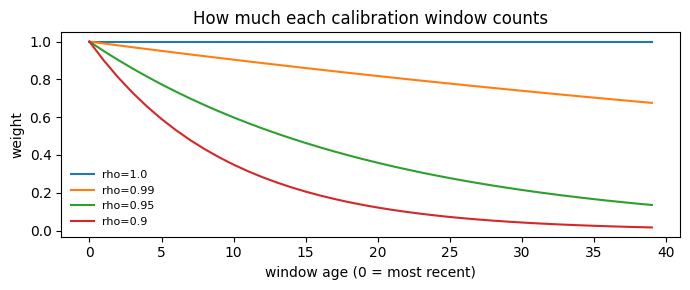

In [ ]:
ages = np.arange(N_WINDOWS)
fig, ax = plt.subplots(figsize=(7, 3))
for i, rho in enumerate(RHOS):
    ax.plot(ages, np.power(rho, ages), color=f"C{i}", lw=1.5, label=f"rho={rho}")
ax.set_xlabel("window age (0 = most recent)")
ax.set_ylabel("weight")
ax.set_title("How much each calibration window counts")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

## What it does to the intervals

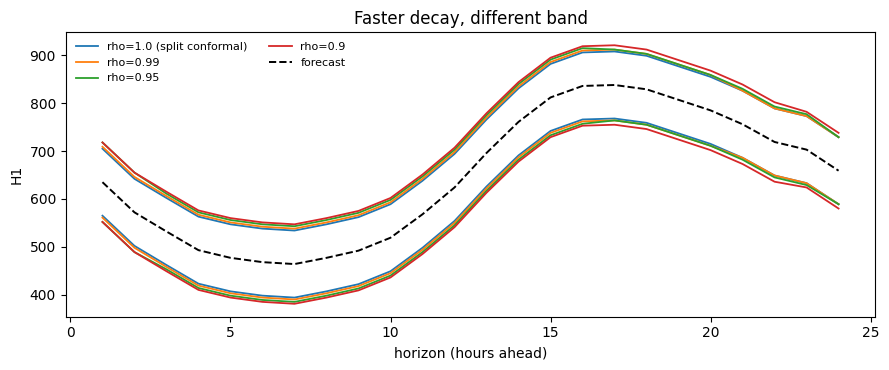

In [ ]:
predictions = {rho: fits[rho].predict(matrix) for rho in RHOS}

series = 0
steps = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, rho in enumerate(RHOS):
    interval = predictions[rho].interval[series, 0]
    label = "rho=1.0 (split conformal)" if rho == 1.0 else f"rho={rho}"
    ax.plot(steps, interval[:, 0], color=f"C{i}", lw=1.3, label=label)
    ax.plot(steps, interval[:, 1], color=f"C{i}", lw=1.3)
ax.plot(steps, predictions[1.0].point[series, 0], color="k", lw=1.4, ls="--", label="forecast")
ax.set_xlabel("horizon (hours ahead)")
ax.set_ylabel(f"{index.series_ids[series]}")
ax.set_title("Faster decay, different band")
ax.legend(fontsize=8, frameon=False, ncol=2)
fig.tight_layout()

In [ ]:
widths = {
    rho: (predictions[rho].interval[..., 1] - predictions[rho].interval[..., 0]).mean(axis=(1, 2))
    for rho in RHOS
}
header = "series   " + "".join(f"{('rho=' + str(r)):>12s}" for r in RHOS)
print(header)
for s, name in enumerate(index.series_ids):
    row = "".join(f"{widths[rho][s]:12.1f}" for rho in RHOS)
    print(f"{name:9s}{row}")

series        rho=1.0    rho=0.99    rho=0.95     rho=0.9
H1              140.0       146.7       155.0       165.3
H10              44.4        63.3       110.9       199.8
H100            539.5       610.9       666.8       811.3
H150            179.9       206.5       217.4       257.4
H200              0.4         0.4         0.4         0.4
H300              0.5         0.5         0.6         0.6
H400             89.3        93.8       133.2       205.0
H50            8804.0      8829.0      8829.8      9336.3


The widths move by series, not uniformly: `rho` reweights each series' own
residual history, so a series whose recent errors are unlike its old ones
changes a lot — `H10` more than quadruples between `rho = 1.0` and `rho = 0.9` —
while a stable one such as `H200` barely moves. A single global multiplier could
not do that.

## Measured coverage

In [ ]:
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = matrix.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(matrix[:, :end])
    truths.append(matrix[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)

for rho in RHOS:
    report = evaluate(fits[rho], histories, truths)
    label = "rho=1.0 (split)" if rho == 1.0 else f"rho={rho}"
    print(
        f"{label:18s} coverage {report.marginal_coverage:6.1%}   "
        f"width {report.mean_interval_width:9.1f}   "
        f"Winkler {report.mean_winkler_score:9.1f}"
    )

rho=1.0 (split)    coverage  85.9%   width    1227.7   Winkler    1369.0
rho=0.99           coverage  89.4%   width    1241.2   Winkler    1360.8
rho=0.95           coverage  92.5%   width    1263.8   Winkler    1338.8
rho=0.9            coverage  94.8%   width    1371.3   Winkler    1429.2


::: {.callout-note}
## The decay pays for itself here, up to a point

Split conformal (`rho = 1.0`) under-covers on this holdout — 85.9% against a 90%
target — because it weights a residual from 40 hours back exactly as heavily as
the most recent one. Every decay setting closes that gap, `rho = 0.99` almost
exactly (89.4%), and the Winkler score, which charges width and misses on one
scale, improves with it, bottoming out at `rho = 0.95` (1338.8 against split's
1369.0).

Past that the trade turns over. `rho = 0.9` buys 94.8% coverage, well beyond what
was asked for, and pays 12% more width than split conformal to get it; its
Winkler score is the worst of the four. That is the shape to expect — forgetting
stale residuals helps while they really are misleading, and costs you effective
sample size once they are not. Measure before tuning `rho`, in both directions.
:::

## When not to use it

- **Your calibration set is small.** Decay throws away effective sample size you
  may not have. Check `effective_sample_size` against `ceil(1/alpha)` before
  trusting the result.
- **Your drift is abrupt rather than gradual.** An exponential decay is a smooth
  forgetting curve. A step change is handled better by [ACI](aci.html), whose
  controller reacts to misses directly.
- **You do not know how fast to forget.** `rho` is as much a tuning parameter as
  ACI's `gamma`, and NexCP has no aggregated variant. If that bothers you, use
  [AgACI](agaci.html).

## References
R. F. Barber, E. J. Candes, A. Ramdas, and R. J. Tibshirani, “Conformal prediction beyond exchangeability,” arXiv.org, 2022. https://arxiv.org/abs/2202.13415.

## Next

- [SPCI](spci.html) — the last online method, and the only one that changes the shape
  of the band rather than its level.
- [Ragged panels](../capabilities/ragged-panels.html) — what the window axis means
  when series have different lengths, which is exactly what NexCP reads.